In [1]:
%matplotlib inline
import torch 
import numpy as np
import pandas as pd
import pickle
import os
import re
import glob
import string
from torch.nn import functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy import stats
from tqdm.notebook import tqdm
import sys
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
#from sklearn.metrics import auc,precision_recall_curve,roc_auc_score,roc_curve,r2_score
sys.path.append('..')
from utils import get_segmentation_indices,segmentation_to_word_list,model_to_path_dict,calculate_cross_entropy

In [2]:
model_name = 'Llama3-8b-instruct'
save_dir = '../../generated'
model_save_dir_name = model_to_path_dict[model_name]['save_dir_name']
model_initial_char = model_to_path_dict[model_name]['initial_char']

moth_output_dir = os.path.join(save_dir,model_save_dir_name,'moth_stories_output')
original_transcript_dir = '../../behavior_data/transcripts/moth_stories'
segmentation_dir = '../../behavior_data/segmentation'


stories = ['pieman','alternateithicatom','odetostepfather','souls','legacy','wheretheressmoke','adventuresinsayingyes','inamoment']
story_to_idx_mapping = {s:stories.index(s)+1 for s in stories}

In [3]:
calibration_file = 'calibration_probs.pkl' # precomputed per-token probabilities, used when logits.pkl is not available
val_stories = []
for story in os.listdir(moth_output_dir):
    if os.path.isdir(os.path.join(moth_output_dir,story)):
        story_files = os.listdir(os.path.join(moth_output_dir,story))
        if 'logits.pkl' not in story_files and calibration_file not in story_files:
            print(story,'does not have logits or precomputed calibration file')
            continue
        if story not in stories:
            val_stories.append(story)
print(len(val_stories))

20


In [ ]:
temps = [1.1,1.2,1.3,1.4]
def get_calibration_probs(story):
    '''
    per-token correct_bool, prob of ground truth token and prob of predicted token for temp 1 (no scaling) and each temp in temps
    returns {temp: {'correct_bool':..., 'prob_of_correct':..., 'prob_of_predicted':...}}
    if logits.pkl exists, computes from logits and saves the result to calibration_file, otherwise loads calibration_file
    '''
    story_dir = os.path.join(moth_output_dir,story)
    if not os.path.exists(os.path.join(story_dir,'logits.pkl')):
        with open(os.path.join(story_dir,calibration_file),'rb') as f:
            return pickle.load(f)
    story_tokens = torch.load(os.path.join(story_dir,'tokens.pkl'),map_location='cpu')
    story_tokens = story_tokens[0,1:].cpu().detach()
    logits = torch.load(os.path.join(story_dir,'logits.pkl'),map_location='cpu')
    logits = logits[0,:-1] # seq len * vocab size
    calibration_probs = {}
    for temp in [1]+temps:
        scaled_logits = logits/temp
        prob = F.softmax(scaled_logits,dim = -1).cpu().detach()
        assert prob.shape[0]==story_tokens.shape[0]
        prob_of_correct = torch.Tensor([prob[i,t] for i,t in enumerate(story_tokens)])
        pred = torch.argmax(prob,dim = 1)
        correct_bool = pred==story_tokens
        prob_of_pred = torch.Tensor([prob[i,t] for i,t in enumerate(pred)])
        calibration_probs[temp] = {'correct_bool':correct_bool,'prob_of_correct':prob_of_correct,'prob_of_predicted':prob_of_pred}
        del scaled_logits,prob
    del logits
    with open(os.path.join(story_dir,calibration_file),'wb') as f:
        pickle.dump(calibration_probs,f)
    return calibration_probs

In [63]:
all_story_calibration_probs = {}
for story in os.listdir(moth_output_dir):
    if os.path.isdir(os.path.join(moth_output_dir,story)):
        all_story_calibration_probs[story] = get_calibration_probs(story)

all_story_correct_bool = []
all_story_prob_of_correct = [] # prob of ground truth token
all_story_prob_of_predicted = [] # prob of predicted token
for story,calibration_probs in all_story_calibration_probs.items():
    all_story_correct_bool.append(calibration_probs[1]['correct_bool'])
    all_story_prob_of_correct.append(calibration_probs[1]['prob_of_correct'])
    all_story_prob_of_predicted.append(calibration_probs[1]['prob_of_predicted'])

In [64]:
all_correct_bool = torch.concat(all_story_correct_bool)
all_story_prob_of_correct = torch.concat(all_story_prob_of_correct)
all_story_prob_of_predicted = torch.concat(all_story_prob_of_predicted)

In [67]:
# define bin edges: [0.0, 0.1, 0.2, ..., 1.0]
bins = torch.linspace(0, 1, steps=11)  # 11 edges → 10 bins

# bin index for each element (0–9)
bin_ids = torch.bucketize(all_story_prob_of_predicted, bins) - 1
#bin_ids = torch.bucketize(all_story_prob_of_correct, bins) - 1
indices_per_bin = [(bin_ids == i).nonzero(as_tuple=True)[0] for i in range(10)]
bin_acc = []
bin_conf = []
for indices in indices_per_bin:
    bin_correct_bool = all_correct_bool[indices].numpy()
    acc= np.mean(bin_correct_bool)
    conf = torch.mean(all_story_prob_of_predicted[indices])
    #conf = torch.mean(all_story_prob_of_correct[indices])
    bin_acc.append(acc)
    bin_conf.append(conf)
bin_acc = np.array(bin_acc)
bin_conf = np.array(bin_conf)

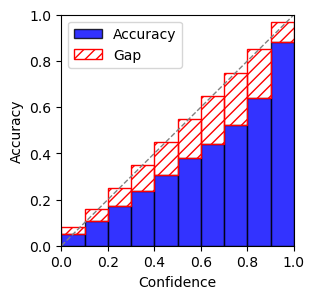

In [68]:
# confidence = mean prob of predicted token in each bin
# accuracy = actual accuracy of the prediction in each bin 
# gap = confidence - accuracy 
bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]
gaps = bin_conf - bin_acc  # calibration gap

fig, ax = plt.subplots(figsize=(3,3))

# --- Blue bars: accuracy ---
ax.bar(bin_centers, bin_acc,
       width=bin_width, color='blue', alpha=0.8,
       edgecolor='black', label='Accuracy')

# --- Pink striped bars: gap (confidence - accuracy) ---
ax.bar(bin_centers, gaps,
       bottom=bin_acc,
       width=bin_width,
       facecolor='none',
       edgecolor='red',
       hatch='///',
       linewidth=1.0,
       label='Gap')

# --- Optional: perfect calibration line ---
ax.plot([0,1],[0,1], color='gray', linestyle='--', linewidth=1)

ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_xlabel("Confidence")
ax.set_ylabel("Accuracy")
ax.legend()

plt.show()

## temperature calibration 

In [96]:
temp_scaled_correct_bool = {}
temp_scaled_prob_of_correct = {} # prob of ground truth token
temp_scaled_prob_of_predicted = {} # prob of predicted token
for temp in temps:
    temp_scaled_correct_bool[temp] = {story:p[temp]['correct_bool'] for story,p in all_story_calibration_probs.items()}
    temp_scaled_prob_of_correct[temp] = {story:p[temp]['prob_of_correct'] for story,p in all_story_calibration_probs.items()}
    temp_scaled_prob_of_predicted[temp] = {story:p[temp]['prob_of_predicted'] for story,p in all_story_calibration_probs.items()}

In [161]:
def binning(correct_bool,pred_prob):
    '''
    bins samples using confidence, i.e. P(prediction) into equally sized bins from 0 to 1
    outputs 1. bin accuracy, array 2. bin confidence, array 3. ECE (expected calibration error), a float summary metric 
    '''
    # define bin edges: [0.0, 0.1, 0.2, ..., 1.0]
    bins = torch.linspace(0, 1, steps=11)  # 11 edges → 10 bins

    # bin index for each element (0–9)
    bin_ids = torch.bucketize(pred_prob, bins) - 1
    indices_per_bin = [(bin_ids == i).nonzero(as_tuple=True)[0] for i in range(10)]
    num_samples_per_bin = np.array([len(b) for b in indices_per_bin])
    bin_acc = []
    bin_conf = []
    for indices in indices_per_bin:
        if len(indices)==0:
            bin_acc.append(np.nan)
            bin_conf.append(np.nan)
        else:
            bin_correct_bool = correct_bool[indices].numpy()
            acc= np.mean(bin_correct_bool)
            #print(pred_prob[indices].shape,acc)
            conf = torch.mean(pred_prob[indices])
            bin_acc.append(acc)
            bin_conf.append(conf)
    bin_acc = np.array(bin_acc)
    bin_conf = np.array(bin_conf)
    
    total_samples = len(correct_bool)
    ece = calculate_ece(bin_acc,bin_conf,num_samples_per_bin,total_samples)
    return bins,bin_acc,bin_conf,ece
def calculate_ece(bin_acc,bin_conf,num_samples_per_bin,total_samples):
    product = np.abs(bin_acc-bin_conf) * num_samples_per_bin/total_samples
    return np.sum(product)
def plot_bin_hist(bins,bin_acc,bin_conf,temp = None):
    # confidence = mean prob of predicted token in each bin
    # accuracy = actual accuracy of the prediction in each bin 
    # gap = confidence - accuracy 
    bin_centers = (bins[:-1] + bins[1:]) / 2
    bin_width = bins[1] - bins[0]
    gaps = bin_conf - bin_acc  # calibration gap

    fig, ax = plt.subplots(figsize=(3,3))

    # --- Blue bars: accuracy ---
    ax.bar(bin_centers, bin_acc,
           width=bin_width, color='blue', alpha=0.8,
           edgecolor='black', label='Accuracy')

    # --- Pink striped bars: gap (confidence - accuracy) ---
    ax.bar(bin_centers, gaps,
           bottom=bin_acc,
           width=bin_width,
           facecolor='none',
           edgecolor='red',
           hatch='///',
           linewidth=1.0,
           label='Gap')

    # --- Optional: perfect calibration line ---
    ax.plot([0,1],[0,1], color='gray', linestyle='--', linewidth=1)

    ax.set_xlim(0,1)
    ax.set_ylim(0,1)
    ax.set_xlabel("Confidence")
    ax.set_ylabel("Accuracy")
    ax.legend()
    if temp is not None:
        ax.set_title(f"temp = {temp}")
    plt.show()
    return

temp: 1.1, ECE: 0.08669380135599494


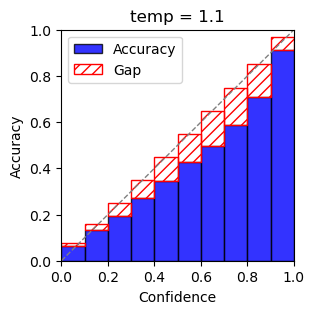

temp: 1.2, ECE: 0.04092897453237699


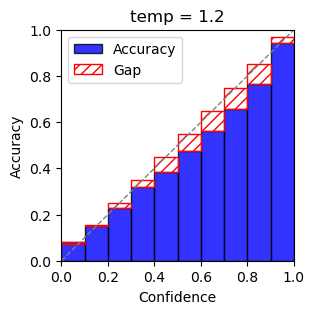

temp: 1.3, ECE: 0.01935383221314931


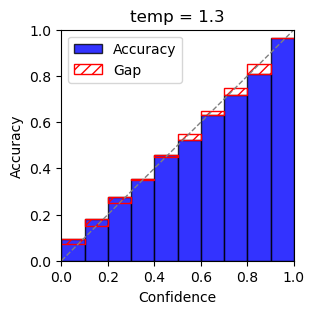

temp: 1.4, ECE: 0.055593412830794366


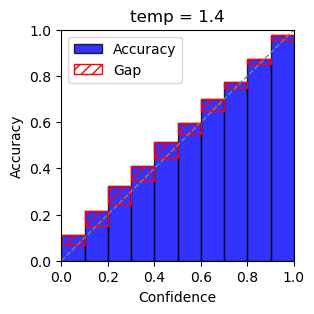

In [162]:
for temp in temps: 
    val_temp_scaled_correct_bool = []
    val_temp_scaled_prob_of_predicted = []
    for story in val_stories:
        val_temp_scaled_correct_bool.append(temp_scaled_correct_bool[temp][story])
        val_temp_scaled_prob_of_predicted.append(temp_scaled_prob_of_predicted[temp][story])
    val_temp_scaled_correct_bool = torch.concat(val_temp_scaled_correct_bool)
    val_temp_scaled_prob_of_predicted = torch.concat(val_temp_scaled_prob_of_predicted)
    bins,bin_acc,bin_conf,ece = binning(val_temp_scaled_correct_bool,val_temp_scaled_prob_of_predicted)
    print(f"temp: {temp}, ECE: {ece}")
    plot_bin_hist(bins,bin_acc,bin_conf,temp)

temp: 1.1, ECE: 0.09138646179150405


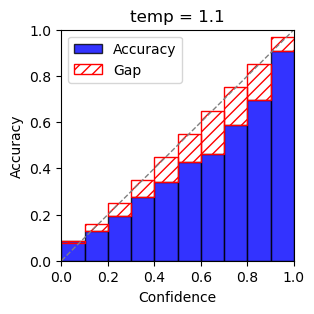

temp: 1.2, ECE: 0.0465201863503275


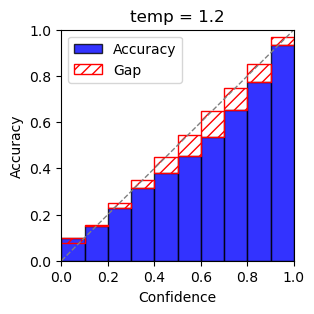

temp: 1.3, ECE: 0.01964429204146158


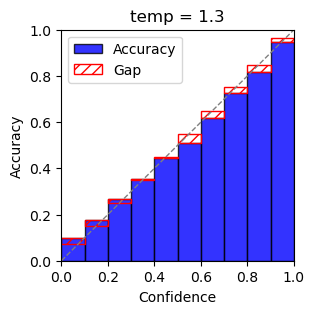

temp: 1.4, ECE: 0.05000950541597347


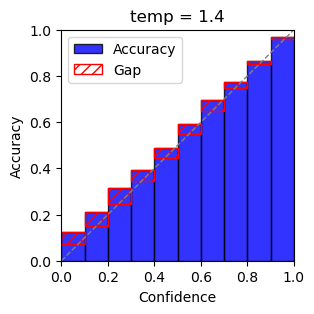

In [163]:
for temp in temps: 
    test_temp_scaled_correct_bool = []
    test_temp_scaled_prob_of_predicted = []
    for story in stories:
        test_temp_scaled_correct_bool.append(temp_scaled_correct_bool[temp][story])
        test_temp_scaled_prob_of_predicted.append(temp_scaled_prob_of_predicted[temp][story])
    test_temp_scaled_correct_bool = torch.concat(test_temp_scaled_correct_bool)
    test_temp_scaled_prob_of_predicted = torch.concat(test_temp_scaled_prob_of_predicted)
    bins,bin_acc,bin_conf,ece = binning(test_temp_scaled_correct_bool,test_temp_scaled_prob_of_predicted)
    print(f"temp: {temp}, ECE: {ece}")
    plot_bin_hist(bins,bin_acc,bin_conf,temp)